In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, roc_curve, average_precision_score, brier_score_loss)

In [2]:
df = pd.read_csv('Dados.csv')
df.head(10)

,safra_obs,renda_mensal,limite,saldo,variacao_saldo_3m,qtd_atrasos_curtos_6m,pagou_minimo_ult_fatura,saldo_default,default_12m
0,2023,4772.63,7437.41,3496.18,0.2938,2,1,0.00,0
1,2025,4322.33,9975.62,5334.88,0.2238,0,0,0.00,0
2,2024,1469.32,3336.31,635.10,0.0475,1,1,0.00,0
3,2024,3107.31,5242.38,862.92,-0.0462,1,0,0.00,0
4,2022,6515.44,15243.24,7553.81,0.0172,0,1,0.00,0
5,2022,2131.84,6410.10,688.13,-0.1633,0,0,0.00,0
6,2022,2762.83,6748.08,5693.34,0.0390,0,0,0.00,0
7,2025,14480.06,22471.18,17661.83,0.1905,1,0,19239.98,1
8,2024,4285.31,13132.77,3343.83,-0.0514,0,0,0.00,0
9,2024,3200.31,7245.08,1517.35,0.1180,1,1,0.00,0


# Engenharia de features

Aqui iremos calcular algumas novas features que podem ser relevantes para o nosso modelo, como:
- Percentual de uso do limite.
- Comprometimento da renda relação ao saldo da dívida.
- Iremos renormalizar a variação do saldo nos últimos 3 meses para entre -1 e 1.

In [3]:
df_ed = df.copy()


df_ed['limite_usado_%'] = df_ed['saldo'] / df_ed['limite']

df_ed['comprometimento_renda_%'] = df_ed['renda_mensal'] / df['saldo']

df_ed['variacao_saldo_3m'] = np.clip(df_ed['variacao_saldo_3m'], -1, 1)

df_ed.head(15)

,safra_obs,renda_mensal,limite,saldo,variacao_saldo_3m,qtd_atrasos_curtos_6m,pagou_minimo_ult_fatura,saldo_default,default_12m,limite_usado_%,comprometimento_renda_%
0,2023,4772.63,7437.41,3496.18,0.2938,2,1,0.00,0,0.470080,1.365098
1,2025,4322.33,9975.62,5334.88,0.2238,0,0,0.00,0,0.534792,0.810202
2,2024,1469.32,3336.31,635.10,0.0475,1,1,0.00,0,0.190360,2.313525
3,2024,3107.31,5242.38,862.92,-0.0462,1,0,0.00,0,0.164605,3.600925
4,2022,6515.44,15243.24,7553.81,0.0172,0,1,0.00,0,0.495551,0.862537
5,2022,2131.84,6410.10,688.13,-0.1633,0,0,0.00,0,0.107351,3.098019
6,2022,2762.83,6748.08,5693.34,0.0390,0,0,0.00,0,0.843698,0.485274
7,2025,14480.06,22471.18,17661.83,0.1905,1,0,19239.98,1,0.785977,0.819850
8,2024,4285.31,13132.77,3343.83,-0.0514,0,0,0.00,0,0.254617,1.281557
9,2024,3200.31,7245.08,1517.35,0.1180,1,1,0.00,0,0.209432,2.109144


# Separação de treino/teste: In-Time e Out-Of-Time
- Dados até 2024 serão usados para treinar a rede.
- Dados de 2025 serão usados para validar o resultado do treino da rede.

In [ ]:
treino = df_ed[df_ed['safra_obs'] < 2025]
teste = df_ed[df_ed['safra_obs'] == 2025]

# Cálculo de IV
- Vamos descobrir quais features mais importam e influenciam o alvo: `default_12m`
- Aqui selecionei todas as colunas numéricas que não dizem respeito a safra e ao alvo.
- A ideia é filtrar as features que tenham um IV > 0.02 e IV < 0.5, assim podemos evitar data leakage.
- As features usadas devem ter relevância suficiente, mas também não podem deixar o resultado vazar para a rede a ponto dela simplesmente "decorar" os resultados.

In [ ]:
candidatas = ['renda_mensal', 'limite', 'saldo', 'variacao_saldo_3m',
       'qtd_atrasos_curtos_6m', 'pagou_minimo_ult_fatura', 'saldo_default',
        'limite_usado_%', 'comprometimento_renda_%']


def calcular_iv(dados, feature, target='default_12m', bins=5):
    aux = dados[[feature, target]].copy()
    aux['faixa'] = pd.qcut(aux[feature], q=bins, duplicates='drop') if aux[feature].nunique() > bins else aux[feature]
    tabela = aux.groupby('faixa', observed=False)[target].agg(total='count', maus='sum')
    tabela['bons'] = tabela['total'] - tabela['maus']
    dist_maus = (tabela['maus'] + 0.5) / (tabela['maus'].sum() + 0.5)
    dist_bons = (tabela['bons'] + 0.5) / (tabela['bons'].sum() + 0.5)
    return round(((dist_maus - dist_bons) * np.log(dist_maus / dist_bons)).sum(), 4)

tabela_iv = pd.DataFrame({
    'feature': candidatas,
    'IV': [calcular_iv(treino, col) for col in candidatas]
}).sort_values(by='IV', ascending=False)

features_selecionadas = tabela_iv[tabela_iv['IV'] >= 0.02]['feature'].tolist()
print("Features selecionadas:", features_selecionadas)

Features selecionadas: ['qtd_atrasos_curtos_6m', 'limite_usado_%', 'variacao_saldo_3m', 'comprometimento_renda_%', 'saldo', 'pagou_minimo_ult_fatura']


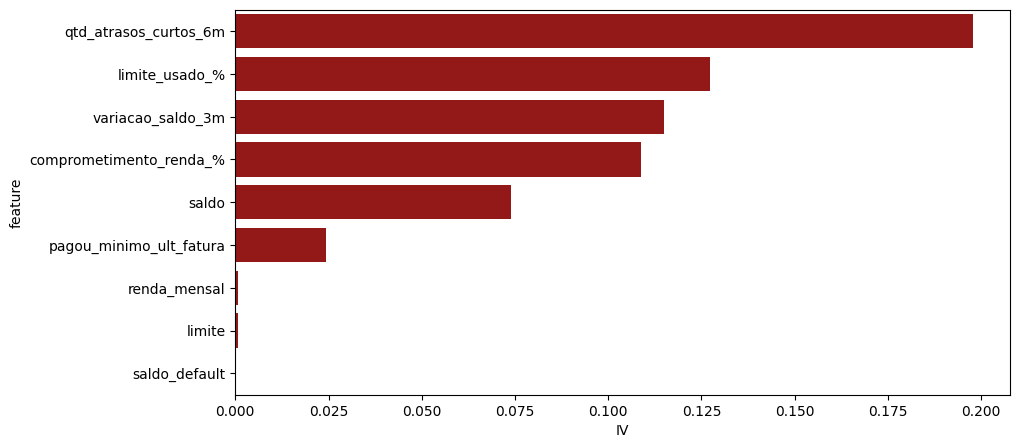

In [16]:
plt.figure(figsize=(10,5))
sns.barplot(data = tabela_iv, y = 'feature', x = 'IV', color= "#A70303")
plt.show()

### Modelagem de Risco de Crédito: Rede Neural (MLP) para Previsão de *Default* (PD)

Nesta etapa, construímos e treinamos um modelo de **Perceptron Multicamadas (MLP)** utilizando TensorFlow/Keras para estimar a **Probabilidade de Default em 12 meses (`default_12m`)**.

#### 1. Pré-processamento e Preparação dos Dados
* **Conversão Numérica:** As *features* selecionadas e a variável-alvo são convertidas para arrays NumPy no formato `float32`, otimizando o consumo de memória e o processamento.
* **Padronização (*Z-score*):** Aplicamos o `StandardScaler` ajustado exclusivamente nos dados de treino (`fit_transform`) e replicado no conjunto de teste (`transform`) para evitar vazamento de dados (*data leakage*) e estabilizar a convergência dos gradientes.

#### 2. Arquitetura da Rede Neural
Para equilibrar capacidade de representação e prevenção contra *overfitting* em dados tabulares, a rede foi estruturada de forma afunilada (`32 -> 16 -> 8 -> 1`):
* **Camadas Ocultas:** Ativação `ReLU` combinada com **regularização L2** (`1e-4`) para penalizar pesos excessivos.
* **Estabilização e Regularização:** Inclusão de `BatchNormalization` para estabilizar as ativações internas e `Dropout(0.3)` para reduzir a co-adaptação entre neurônios.
* **Camada de Saída:** Ativação `sigmoid`, retornando valores contínuos no intervalo $[0, 1]$ interpretáveis como probabilidades de inadimplência.

#### 3. Treinamento, Otimização e Avaliação
* **Função de Perda e Métricas:** Otimizador `Adam` minimizando a `binary_crossentropy`, com monitoramento de **Acurácia** e **AUC-ROC** (métrica principal de discriminação em risco de crédito).
* **Callbacks de Controle:**
  * `EarlyStopping`: Interrompe o treinamento após 15 épocas sem ganho na `val_auc`, restaurando os melhores pesos obtidos.
  * `ReduceLROnPlateau`: Reduz a taxa de aprendizado pela metade (`factor=0.5`) caso a `val_auc` estagne por 5 épocas, permitindo um ajuste fino (*fine-tuning*).
* **Validação Final:** O modelo restaurado é avaliado de forma isenta no conjunto de teste (`X_test`, `y_test`).

In [ ]:
X_train = treino[features_selecionadas].to_numpy(dtype=np.float32)
y_train = treino['default_12m'].to_numpy(dtype=np.float32).reshape(-1, 1)

X_test = teste[features_selecionadas].to_numpy(dtype=np.float32)
y_test = teste['default_12m'].to_numpy(dtype=np.float32).reshape(-1, 1)


scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


tf.keras.utils.set_random_seed(42)
reg = tf.keras.regularizers.l2(1e-4)


modelo = tf.keras.Sequential([
    tf.keras.Input(shape=(len(features_selecionadas),)),
    tf.keras.layers.Dense(32, activation='relu', kernel_regularizer=reg),
    tf.keras.layers.Dense(16, activation='relu', kernel_regularizer=reg),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(8, activation='relu', kernel_regularizer=reg),
    tf.keras.layers.Dense(1, activation='sigmoid')
])



modelo.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy', tf.keras.metrics.AUC(name='auc')])


historico = modelo.fit(X_train, y_train, epochs=500, batch_size=256, validation_split=0.2, verbose=1, callbacks=[
        tf.keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=15,
                                         restore_best_weights=True),

        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_auc', mode='max',
                                             factor=0.5, patience=5, min_lr=1e-5),
    ])



resultado = modelo.evaluate(X_test, y_test, verbose=0)

print("Resultados:", dict(zip(modelo.metrics_names, resultado)))


Epoch 1/500
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7561 - auc: 0.6179 - loss: 0.5376 - val_accuracy: 0.8066 - val_auc: 0.6966 - val_loss: 0.4813 - learning_rate: 0.0010
Epoch 2/500
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8147 - auc: 0.6639 - loss: 0.4634 - val_accuracy: 0.8073 - val_auc: 0.6992 - val_loss: 0.4627 - learning_rate: 0.0010
Epoch 3/500
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8176 - auc: 0.6772 - loss: 0.4526 - val_accuracy: 0.8076 - val_auc: 0.7018 - val_loss: 0.4563 - learning_rate: 0.0010
Epoch 4/500
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8195 - auc: 0.6857 - loss: 0.4470 - val_accuracy: 0.8085 - val_auc: 0.7046 - val_loss: 0.4544 - learning_rate: 0.0010
Epoch 5/500
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8193 - auc: 0.6911 - loss: 0.4442 - val_accuracy: 0.8074 - val_auc: 0.7059 - val_loss: 0.4537 - learning_rate: 0.0010
Epoch 6/500
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8199 - a

# Teste com cliente aleatório

In [ ]:
cliente = teste.sample(1)

X_cliente = cliente[features_selecionadas].to_numpy(dtype=np.float32)

X_cliente = scaler.transform(X_cliente).astype(np.float32)

pd_cliente = modelo.predict(X_cliente, verbose=0)[0, 0]

print(f"PD do cliente: {pd_cliente:.4%}")


print("Default observado:", int(cliente['default_12m'].iloc[0]))

PD do cliente: 15.5894%
Default observado: 0


# Métricas

In [ ]:
def psi(ref, cur, n_bins=10, eps=1e-6):

    ref, cur = np.ravel(ref), np.ravel(cur)
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, n_bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    p_ref = np.histogram(ref, edges)[0] / len(ref)
    p_cur = np.histogram(cur, edges)[0] / len(cur)
    p_ref, p_cur = np.clip(p_ref, eps, None), np.clip(p_cur, eps, None)

    return np.sum((p_cur - p_ref) * np.log(p_cur / p_ref))

def faixa_psi(v):
    return "estável" if v < 0.10 else "atenção" if v < 0.25 else "mudança significativa"

# Probabilidades previstas 
pd_train = modelo.predict(X_train, verbose=0).ravel()
pd_pred  = modelo.predict(X_test,  verbose=0).ravel()
y_true   = y_test.ravel()

# Métricas
auc = roc_auc_score(y_true, pd_pred)
gini = 2 * auc - 1
fpr, tpr, _ = roc_curve(y_true, pd_pred)
ks = np.max(tpr - fpr)
brier = brier_score_loss(y_true, pd_pred)
ap = average_precision_score(y_true, pd_pred)

print(f"AUC: {auc:.4f}")
print(f"Gini: {gini:.4f}")
print(f"KS: {ks:.4f}")
print(f"Brier Score: {brier:.4f}")
print(f"Average Precision: {ap:.4f}")
print("\nTaxa de inadimplência observada:", y_true.mean())
print("PD média prevista:", pd_pred.mean())

# PSI do score
psi_score = psi(pd_train, pd_pred)
print(f"\nPSI do score: {psi_score:.4f} ({faixa_psi(psi_score)})")

# PSI por variável
psi_vars = pd.Series({f: psi(X_train[:, j], X_test[:, j]) for j, f in enumerate(features_selecionadas)}).sort_values(ascending=False)

print("\nPSI por variável:")
print(pd.DataFrame({"PSI": psi_vars, "faixa": psi_vars.map(faixa_psi)}))

AUC: 0.7043
Gini: 0.4085
KS: 0.2983
Brier Score: 0.1382
Average Precision: 0.3778

Taxa de inadimplência observada: 0.18748327
PD média prevista: 0.18699887

PSI do score: 0.0010 (estável)

PSI por variável:
                              PSI    faixa
saldo                    0.001223  estável
variacao_saldo_3m        0.001213  estável
comprometimento_renda_%  0.000533  estável
limite_usado_%           0.000520  estável
qtd_atrasos_curtos_6m    0.000222  estável
pagou_minimo_ult_fatura  0.000000  estável
